# 03 – How fast is Türkiye shifting to electric cars?

**Business question 1.** The shift is measured in two ways, because they tell different stories:

- **New cars (sales):** what people are buying today. This shows the *speed* of change.
- **Registered cars (the fleet):** all cars on the road. This drives *charging demand*. Cars stay on the road for many years, so the fleet changes much more slowly than sales.

Data: `national_monthly.csv` from notebook 02 (TÜİK registered cars by fuel type and first registrations; EPDK monthly electric vehicle sales).

Method: simple shares, year-on-year changes and growth rates. No forecasting model is used.

**Limitation:** open data has no fuel split for *new* cars, so on the sales side only the electric share can be shown (EPDK electric sales ÷ TÜİK new cars), not the full fuel mix as in the UK project.

In [1]:
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

In [2]:
national = pd.read_csv(PROCESSED + "national_monthly.csv")
# Each month is plotted on its first day, so that a point sits right above its month label
national["date"] = pd.PeriodIndex(national["month"], freq="M").start_time
national = national.set_index("month")
LATEST = "2026-09"

## 1. Fleet: fuel mix of registered cars, 2011 – September 2026

Share of each fuel type in all registered cars, at the end of each year and in September 2026. TÜİK reports electric cars separately from 2011 and hybrids from 2012.

In [3]:
fuel_groups = ["cars_petrol", "cars_diesel", "cars_lpg", "cars_hybrid", "cars_electric"]
year_ends = national[(national.index.str.endswith("-12") & (national.index >= "2011-12")) | (national.index == LATEST)]
fleet_mix = year_ends.set_index("date")[fuel_groups].div(year_ends.set_index("date")["cars_total"], axis=0) * 100
fleet_mix.index = fleet_mix.index.strftime("%Y-%m")
fleet_mix.round(1)

,cars_petrol,cars_diesel,cars_lpg,cars_hybrid,cars_electric
date,,,,,
2011-12,37.4,21.6,40.2,NaN,0.0
2012-12,33.9,24.3,41.3,0.0,0.0
2013-12,31.1,26.9,41.5,0.0,0.0
2014-12,29.0,29.2,41.4,0.0,0.0
2015-12,27.6,31.6,40.3,0.0,0.0
2016-12,26.8,33.6,39.2,0.0,0.0
2017-12,25.9,35.4,38.4,0.0,0.0
2018-12,24.9,36.8,37.9,0.0,0.0
2019-12,24.2,38.1,37.3,0.1,0.0


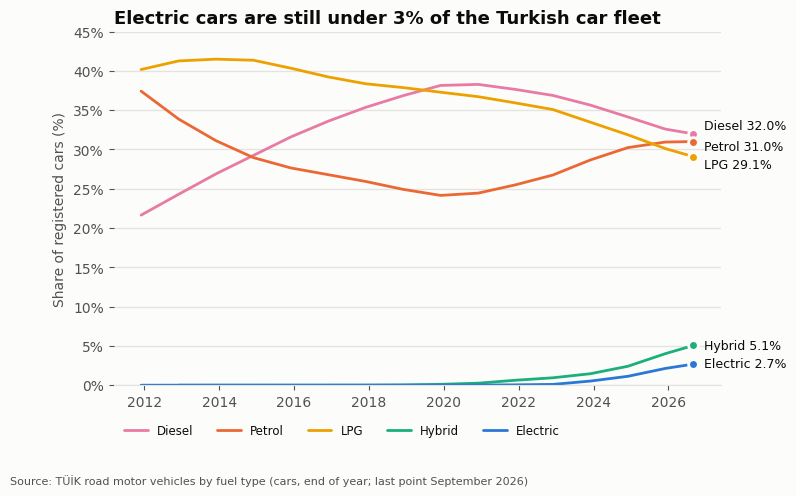

In [4]:
labels = {
    "cars_diesel": ("Diesel", MAGENTA),
    "cars_petrol": ("Petrol", ORANGE),
    "cars_lpg": ("LPG", YELLOW),
    "cars_hybrid": ("Hybrid", AQUA),
    "cars_electric": ("Electric", BLUE),
}
# Vertical label offsets (points) so that close lines do not overlap
label_offset = {"cars_diesel": 6, "cars_petrol": -4, "cars_lpg": -6}
mix = year_ends.set_index("date")[fuel_groups].div(year_ends.set_index("date")["cars_total"], axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 5.2))
for col, (label, color) in labels.items():
    ax.plot(mix.index, mix[col], color=color, label=label)
    ax.plot(mix.index[-1], mix[col].iloc[-1], "o", color=color, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{label} {mix[col].iloc[-1]:.1f}%", (mix.index[-1], mix[col].iloc[-1]),
                xytext=(8, label_offset.get(col, 0)), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("Electric cars are still under 3% of the Turkish car fleet")
ax.set_ylabel("Share of registered cars (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 45)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=5, frameon=False, fontsize=8.5)
plt.subplots_adjust(right=0.8, bottom=0.2)
add_source(fig, "Source: TÜİK road motor vehicles by fuel type (cars, end of year; last point September 2026)")
fig.savefig(FIGURES + "01_car_fleet_fuel_mix.png", dpi=200)
plt.show()

**How to read this chart:** each line is one fuel type's share of all registered cars. The lines add up to almost 100% (a small "unknown fuel" group is not shown). The last point is September 2026.

**What it shows**
- Türkiye's fleet is split almost evenly between **diesel (32%), petrol (31%) and LPG (29%)**. LPG is a Turkish specificity: it was 40% of the fleet in 2011 and has been falling slowly since.
- **Electric cars are 2.7% of the fleet** (486,359 of 18.1 million in September 2026). They were 0.5% at the end of 2023, so the share has grown five-fold in under three years, but from a very low base.
- **Hybrids (5.1%) are growing faster than electric cars in number.** In the last year the fleet grew by 1.09 million cars: hybrids added 314,000 and electric cars 167,000. Many buyers leaving petrol, diesel and LPG choose a hybrid, which needs no charger.

## 2. Electric cars on the road

In [5]:
ev = national.loc["2019-01":, ["date", "cars_electric"]]

latest = national.loc[LATEST, "cars_electric"]
year_ago = national.loc["2025-09", "cars_electric"]
four_years_ago = national.loc["2022-09", "cars_electric"]

# Average annual growth over four years (compound annual growth rate)
cagr = (latest / four_years_ago) ** (1 / 4) - 1

print(f"Electric cars, September 2026:      {latest:,.0f}")
print(f"Growth in the last year:            {latest / year_ago - 1:.0%}")
print(f"Times larger than four years ago:   {latest / four_years_ago:.0f}x")
print(f"Average yearly growth, 2022-2026:   {cagr:.0%}")

# Cars added per calendar year (December to December)
dec = national.loc[national.index.str.endswith("-12"), "cars_electric"]
print("\nElectric cars added per year:")
print(dec.diff().loc["2020-12":].astype(int).to_string())

Electric cars, September 2026:      486,359
Growth in the last year:            52%
Times larger than four years ago:   45x
Average yearly growth, 2022-2026:   159%

Electric cars added per year:
month
2020-12      1621
2021-12      3470
2022-12      8285
2023-12     65491
2024-12    103733
2025-12    186815


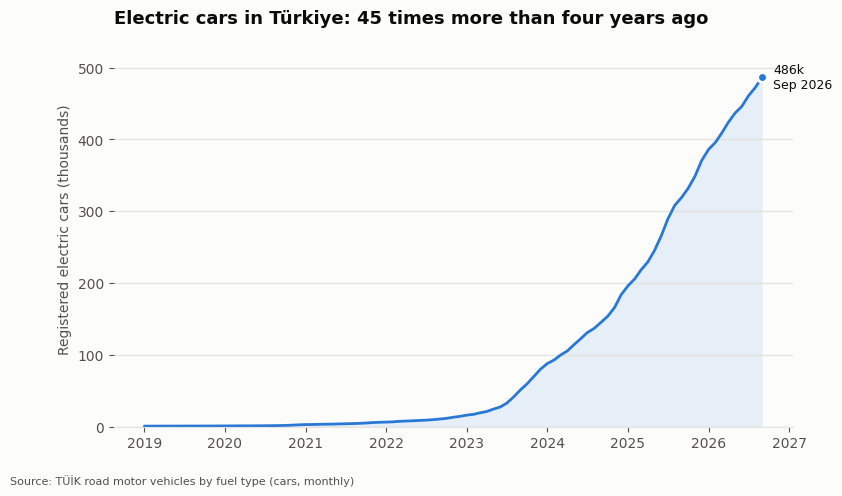

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(ev["date"], ev["cars_electric"] / 1000, color=BLUE)
ax.fill_between(ev["date"], ev["cars_electric"] / 1000, color=BLUE, alpha=0.1, linewidth=0)
last = ev.iloc[-1]
ax.plot(last["date"], last["cars_electric"] / 1000, "o", color=BLUE, markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{last['cars_electric'] / 1000:.0f}k\nSep 2026", (last["date"], last["cars_electric"] / 1000),
            xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("Electric cars in Türkiye: 45 times more than four years ago")
ax.set_ylabel("Registered electric cars (thousands)")
ax.set_ylim(0, 550)
plt.subplots_adjust(right=0.88, bottom=0.12)
add_source(fig, "Source: TÜİK road motor vehicles by fuel type (cars, monthly)")
fig.savefig(FIGURES + "02_ev_cars_on_road.png", dpi=200)
plt.show()

**How to read this chart:** the number of registered electric cars at the end of each month, in thousands.

**What it shows**
- **486,359 electric cars** were registered in September 2026, up **52% in one year**.
- Four years earlier (September 2022) there were only 10,820: the fleet is **45 times larger**. This is much faster than in the UK (4 times in four years), because Türkiye started from almost zero.
- The take-off came in **2023** (from 14,552 to 80,043 cars), the year domestic Togg deliveries and Tesla sales started. Since then each year has added more cars than the year before: 66,000 in 2023, 104,000 in 2024, 187,000 in 2025.
- Growth in percent is slowing (it is easier to double from a small base), but the **number added each month is still rising**. That number is what drives new charging demand.

## 3. Sales vs fleet: electric share, monthly

**Sales share** = EPDK electric vehicle sales ÷ TÜİK new cars registered, June 2023 – September 2026. The two sources are different, so first a check: if EPDK sales are right, they should be close to the monthly increase in TÜİK's electric car count (cars are rarely scrapped this young).

In [7]:
sales = national.loc["2023-06":, ["date", "new_cars", "ev_sales_epdk", "cars_electric", "cars_total"]].copy()
sales["fleet_increase"] = national["cars_electric"].diff().loc["2023-06":]
sales["year"] = sales.index.str[:4]

check = sales.groupby("year")[["ev_sales_epdk", "fleet_increase"]].sum()
check["difference_%"] = (check["ev_sales_epdk"] / check["fleet_increase"] - 1) * 100
check.round(1)

,ev_sales_epdk,fleet_increase,difference_%
year,,,
2023,55943.0,55544.0,0.7
2024,104809.0,103733.0,1.0
2025,188358.0,186815.0,0.8
2026,125501.0,115768.0,8.4


The two sources agree within 1% in 2023–2025. In 2026 EPDK sales are 8% higher than the fleet increase, probably because EPDK also counts some non-car electric vehicles (notebook 01) or because some cars left the register (export, scrapping). The gap is small enough to use EPDK sales for the sales share, with this caveat.

In [8]:
sales["ev_share_sales"] = sales["ev_sales_epdk"] / sales["new_cars"] * 100
sales["ev_share_fleet"] = sales["cars_electric"] / sales["cars_total"] * 100

annual = sales.groupby("year")[["ev_sales_epdk", "new_cars"]].sum()
annual["ev_share_sales"] = annual["ev_sales_epdk"] / annual["new_cars"] * 100
print("Electric share of new cars by year (2023: June-December, 2026: January-September):")
print(annual["ev_share_sales"].round(1).to_string())

# Same month, one year apart: removes seasonal effects
print("\nSame month, one year apart:")
print(sales.loc[["2024-09", "2025-09", "2026-09", "2024-06", "2025-06", "2026-06"], "ev_share_sales"].round(1).to_string())

Electric share of new cars by year (2023: June-December, 2026: January-September):
year
2023     9.5
2024    10.3
2025    16.8
2026    18.9

Same month, one year apart:
month
2024-09    13.6
2025-09    13.7
2026-09    23.8
2024-06    11.3
2025-06    28.6
2026-06    14.7


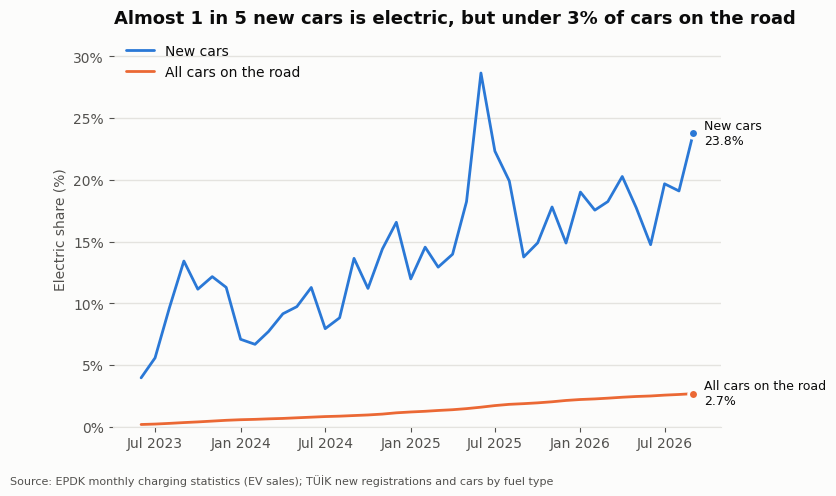

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.2))
series = [
    ("ev_share_sales", "New cars", BLUE),
    ("ev_share_fleet", "All cars on the road", ORANGE),
]
for col, label, color in series:
    ax.plot(sales["date"], sales[col], color=color, label=label)
    last = sales.iloc[-1]
    ax.plot(last["date"], last[col], "o", color=color, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{label}\n{last[col]:.1f}%", (last["date"], last[col]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("Almost 1 in 5 new cars is electric, but under 3% of cars on the road")
ax.set_ylabel("Electric share (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 32)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", frameon=False)
plt.subplots_adjust(right=0.8, bottom=0.12)
add_source(fig, "Source: EPDK monthly charging statistics (EV sales); TÜİK new registrations and cars by fuel type")
fig.savefig(FIGURES + "03_ev_share_sales_vs_fleet.png", dpi=200)
plt.show()

**How to read this chart:** the blue line is the share of *new* cars that are electric in each month. The orange line is the share of *all* registered cars that are electric at the end of each month.

**What it shows**
- **Sales are far ahead of the fleet.** In January–September 2026, **18.9% of new cars were electric**, but only 2.7% of cars on the road.
- **The sales share is rising year by year:** 10.3% in 2024, 16.8% in 2025, 18.9% in 2026 so far. Comparing the same month removes seasonal effects: September went from 13.6% (2024) to 13.7% (2025) to **23.8% (2026)**. Not every month rises, though (see June below).
- The blue line jumps a lot from month to month (e.g. a peak of 28.6% in June 2025, then 14.7% in June 2026). New model launches, price and tax changes and year-end campaigns move monthly sales. Yearly figures are more reliable than any single month.
- **The fleet share rises slowly but steadily**, about 0.06 percentage points per month in 2026.

## Answer to question 1

- **Sales are shifting fast.** About **1 in 5 new cars** sold in Türkiye in 2026 is electric (18.9% in January–September), up from about 1 in 10 in 2024. For comparison, the UK was at 23% in 2025.
- **The fleet is shifting slowly.** Electric cars are **2.7%** of the 18.1 million cars on the road (UK: 5.8%). Even at today's sales share, most cars on Turkish roads will burn petrol, diesel or LPG for many years.
- **The number of electric cars is growing very fast**: 486,000 in September 2026, +52% in one year and 45 times more than four years ago. Each year adds more cars than the year before (187,000 in 2025).
- **Hybrids are the other big winner.** They add almost twice as many cars to the fleet as electric cars, without needing a charger.

**What this means for charging**
- Charging demand grows with the *fleet*, not with sales. With about 15,000–20,000 new electric cars a month, the network has to keep adding capacity every month just to stay at today's level of service.
- Because the fleet is still small, Türkiye has a time window to build the network ahead of demand, as long as investment keeps pace with the growth shown here. Notebook 04 checks whether it does.